## Data loading and Exploration

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("C:/Users/zoran/OneDrive/Desktop/telco-customer-churn/data/raw/telco_customer_churn.csv")

In [7]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [10]:
df["TotalCharges"].info()

<class 'pandas.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: TotalCharges
Non-Null Count  Dtype
--------------  -----
7043 non-null   str  
dtypes: str(1)
memory usage: 95.6 KB


In [11]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = df["TotalCharges"].astype(float)
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [12]:
df["TotalCharges"].value_counts()

TotalCharges
20.200      11
1397.475    11
19.750       9
19.900       8
20.050       8
            ..
1990.500     1
7362.900     1
346.450      1
306.600      1
6844.500     1
Name: count, Length: 6531, dtype: int64

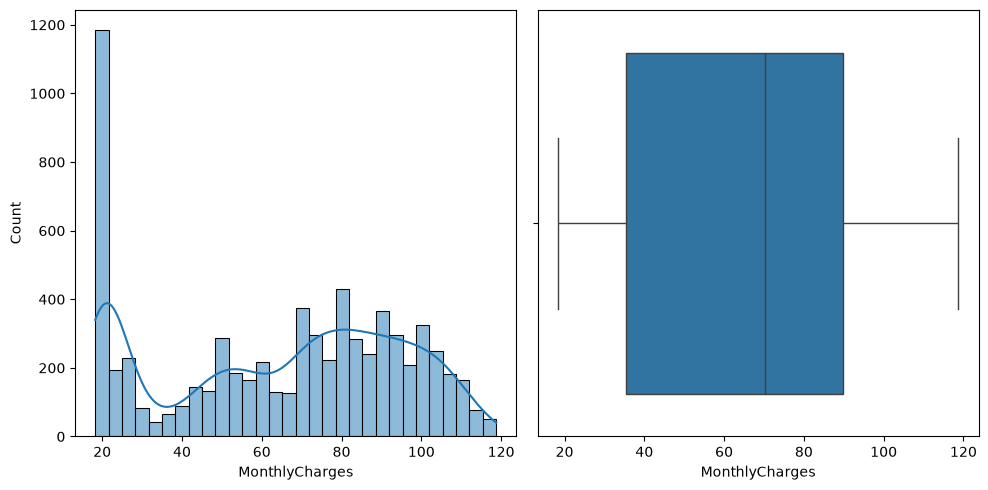

In [13]:
fig, axes = plt.subplots(1, 2, figsize = (10,5))

sns.histplot(data=df, x = "MonthlyCharges", bins=30, kde=True, ax=axes[0])
sns.boxplot(data=df, x = "MonthlyCharges", ax=axes[1])

plt.tight_layout()
plt.show()

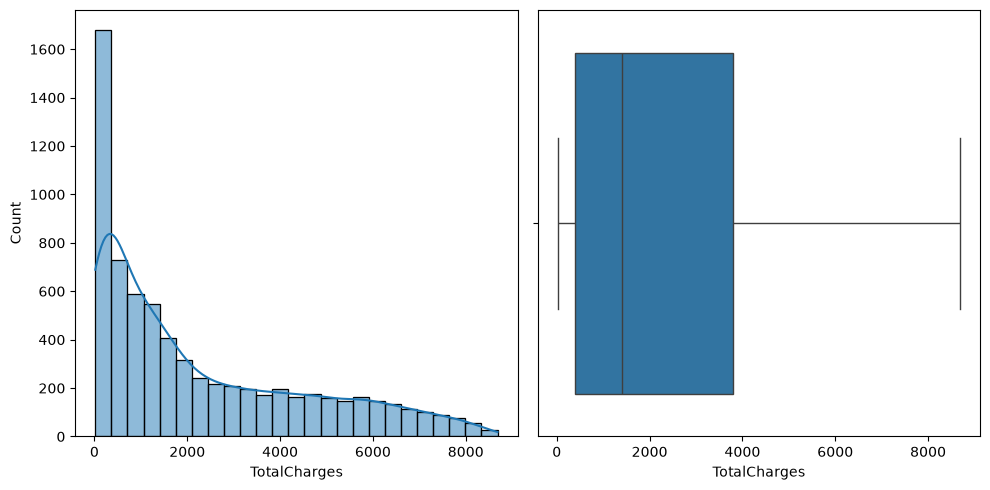

In [14]:
fig, axes = plt.subplots(1, 2, figsize = (10, 5))

sns.histplot(data = df, x = "TotalCharges", kde=True, ax = axes[0])
sns.boxplot(data=df, x = "TotalCharges", ax=axes[1])

plt.tight_layout()
plt.show()

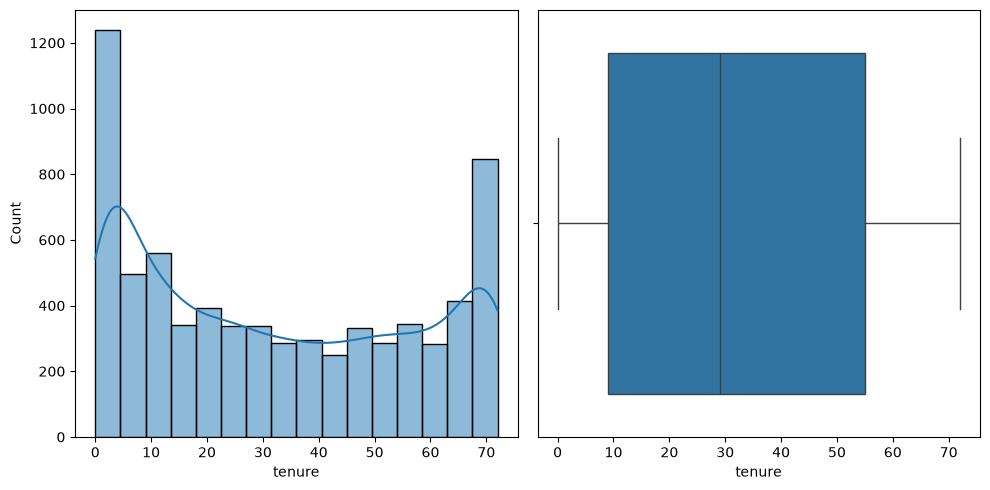

In [15]:
fig, axes = plt.subplots(1, 2 , figsize = (10, 5))

sns.histplot(data = df, x = "tenure", kde=True, ax=axes[0])
sns.boxplot(data = df, x = "tenure", ax=axes[1])

plt.tight_layout()

plt.show()

## Preprocessing

In [16]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

encoder = OneHotEncoder()

binary_cols = ["gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
categorical_cols = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                    "Contract", "PaymentMethod"]

def binary_cols_transform(dataframe):
    return dataframe.replace({
        "Yes": 1, "No": 0,
        "Male": 1, "Female": 0
    }).astype(int)

In [17]:
df = df.drop("customerID", axis = 1)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ("binary", FunctionTransformer(binary_cols_transform, feature_names_out="one-to-one"), binary_cols)
    ], 
    remainder="passthrough",
    verbose_feature_names_out=False
    )

In [18]:
df_transformed = preprocessor.fit_transform(df)
df_transformed = pd.DataFrame(
    df_transformed,
    columns=preprocessor.get_feature_names_out()
)

df_transformed = df_transformed.apply(pd.to_numeric)

In [19]:
df_transformed.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   MultipleLines_No phone service         7043 non-null   float64
 1   MultipleLines_Yes                      7043 non-null   float64
 2   InternetService_Fiber optic            7043 non-null   float64
 3   InternetService_No                     7043 non-null   float64
 4   OnlineSecurity_No internet service     7043 non-null   float64
 5   OnlineSecurity_Yes                     7043 non-null   float64
 6   OnlineBackup_No internet service       7043 non-null   float64
 7   OnlineBackup_Yes                       7043 non-null   float64
 8   DeviceProtection_No internet service   7043 non-null   float64
 9   DeviceProtection_Yes                   7043 non-null   float64
 10  TechSupport_No internet service        7043 non-null   float64
 11  TechSupport_Yes

In [20]:
float_cols = df_transformed.select_dtypes(include="float64").columns

binary_float_cols = [
    col for col in float_cols if df_transformed[col].isin([0.0, 1.0]).all()
]

df_transformed[binary_float_cols] = df_transformed[binary_float_cols].astype(int)

## Cleaning & VIF

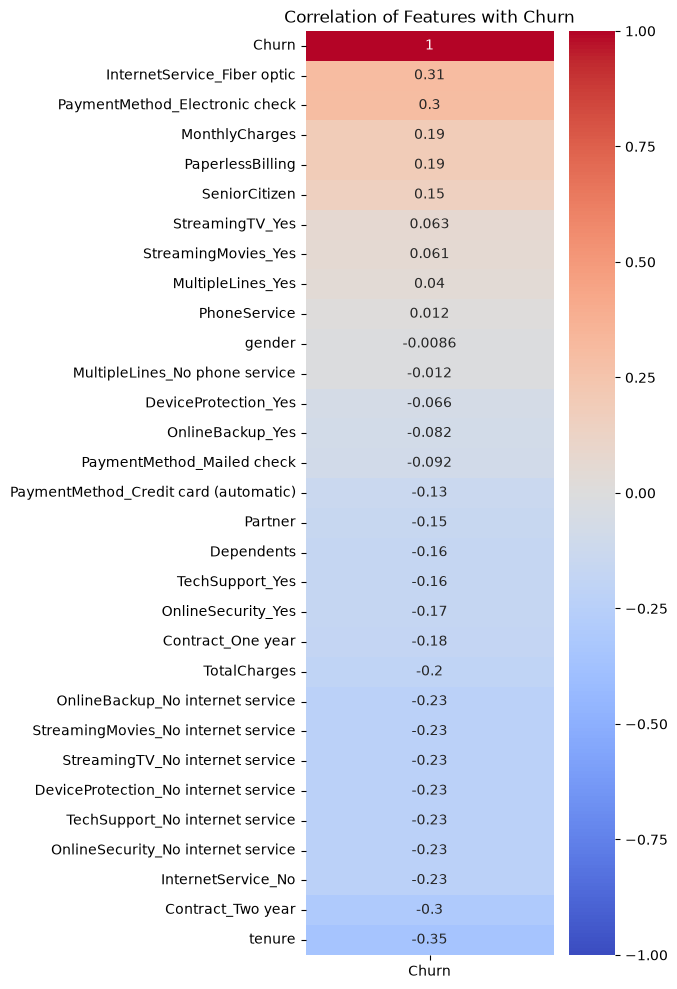

In [21]:
corr_df = df_transformed.corr(numeric_only=True)

churn_corr = corr_df[["Churn"]].sort_values(by="Churn", ascending=False)

plt.figure(figsize=(4,12))
sns.heatmap(data=churn_corr, cmap="coolwarm", annot=True, vmin=-1, vmax=1)
plt.title("Correlation of Features with Churn")
plt.show()

In [22]:
drop_cols = [
    col for col in df_transformed.columns
    if "No internet service" in col
    or "No phone service" in col
]

df_transformed = df_transformed.drop(columns=drop_cols)

In [23]:
df_transformed.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   MultipleLines_Yes                      7043 non-null   int64  
 1   InternetService_Fiber optic            7043 non-null   int64  
 2   InternetService_No                     7043 non-null   int64  
 3   OnlineSecurity_Yes                     7043 non-null   int64  
 4   OnlineBackup_Yes                       7043 non-null   int64  
 5   DeviceProtection_Yes                   7043 non-null   int64  
 6   TechSupport_Yes                        7043 non-null   int64  
 7   StreamingTV_Yes                        7043 non-null   int64  
 8   StreamingMovies_Yes                    7043 non-null   int64  
 9   Contract_One year                      7043 non-null   int64  
 10  Contract_Two year                      7043 non-null   int64  
 11  PaymentMethod_C

In [24]:
X = df_transformed.drop("Churn", axis=1)
bool_cols = X.select_dtypes(include="bool").columns
X[bool_cols] = X[bool_cols].astype(int)

In [25]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [26]:
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by="VIF", ascending=False)

print(vif_data)

                                  feature         VIF
21                         MonthlyCharges  865.066041
1             InternetService_Fiber optic  148.263438
2                      InternetService_No  104.219371
17                           PhoneService   34.861870
8                     StreamingMovies_Yes   24.109793
7                         StreamingTV_Yes   24.056872
22                           TotalCharges   10.675411
20                                 tenure    7.407607
0                       MultipleLines_Yes    7.274160
5                    DeviceProtection_Yes    6.922501
4                        OnlineBackup_Yes    6.783323
6                         TechSupport_Yes    6.467578
3                      OnlineSecurity_Yes    6.336238
10                      Contract_Two year    2.628609
12         PaymentMethod_Electronic check    1.976212
13             PaymentMethod_Mailed check    1.860564
9                       Contract_One year    1.621968
11  PaymentMethod_Credit car

## Machine learning

In [27]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [28]:
y = df_transformed["Churn"]
y.info()

<class 'pandas.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: Churn
Non-Null Count  Dtype
--------------  -----
7043 non-null   int64
dtypes: int64(1)
memory usage: 55.2 KB


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

THRESHOLD = 0.3

### RandomForest Classifier

In [30]:
randomforest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

randomforest.fit(X_train, y_train)

proba = randomforest.predict_proba(X_test)[:,1]
y_pred = (proba >= THRESHOLD).astype(int)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.929     0.659     0.771      1035
           1      0.477     0.861     0.614       374

    accuracy                          0.713      1409
   macro avg      0.703     0.760     0.692      1409
weighted avg      0.809     0.713     0.729      1409



### LightGBM classifier

In [31]:
from lightgbm import LGBMClassifier
import time

In [32]:
lightgbm = LGBMClassifier(
    max_depth=-1,
    n_estimators=500,
    random_state=42,
    learning_rate=0.5,
    n_jobs=-1,
    class_weight="balanced"
)

# Training timer
start_train = time.time()
lightgbm.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"Training time: {train_time:.2f}")

# Prediction timer
start_prediction = time.time()
proba = lightgbm.predict_proba(X_test)[:,1]
y_pred = (proba >= THRESHOLD).astype(int)
prediction_time = time.time() - start_prediction
print(f"Prediction time: {prediction_time}")


print(classification_report(y_test, y_pred, digits=3))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001151 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 623
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Training time: 1.19
Prediction time: 0.02253556251525879
              precision    recall  f1-score   support

           0      0.849     0.829     0.839      1035
           1      0.555     0.591     0.573       374

    accuracy                          0.766      1409
   macro avg      0.702     0.710     0.706      1409
weighted avg      0.771     0.766     0

In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score

proba = lightgbm.predict_proba(X_test)[:,1]

print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    preds = (proba >= thresh).astype(int)
    precision = precision_score(y_test, preds, pos_label=1)
    recall = recall_score(y_test, preds, pos_label=1)
    f1 = f1_score(y_test, preds, pos_label=1)
    print(f"{thresh:<8}{precision:<8.3f}{recall:<8.3f}{f1:<8.3f}")

Thresh  Prec_1  Rec_1   F1_1    
0.25    0.555   0.604   0.579   
0.3     0.555   0.591   0.573   
0.35    0.564   0.588   0.576   
0.4     0.563   0.570   0.566   
0.45    0.569   0.561   0.565   
0.5     0.572   0.553   0.562   


### XGBoost Classifier

In [34]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(scale_pos_weight)

2.768561872909699


In [35]:
xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss'
)

#Training timer
start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"Training time: {train_time}")

#Prediction timer
start_prediction = time.time()
xgb_proba = xgb.predict_proba(X_test)[:,1]
y_pred = (xgb_proba >= THRESHOLD).astype(int)
prediction_time = time.time() - start_prediction
print(f"Prediction time: {prediction_time}")

print(classification_report(y_test, y_pred, digits=3))

Training time: 0.8238823413848877
Prediction time: 0.01331639289855957
              precision    recall  f1-score   support

           0      0.910     0.688     0.784      1035
           1      0.485     0.813     0.607       374

    accuracy                          0.721      1409
   macro avg      0.698     0.750     0.696      1409
weighted avg      0.798     0.721     0.737      1409



In [36]:
print("Threshold tuning for XGBoost")

print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    preds = (proba >= thresh).astype(int)
    precision = precision_score(y_test, preds, pos_label=1)
    rec = recall_score(y_test, preds, pos_label=1)
    f1 = f1_score(y_test, preds, pos_label=1)
    print(f"{thresh:<8}{precision:<8.3f}{rec:<8.3f}{f1:<8.3f}")

Threshold tuning for XGBoost
Thresh  Prec_1  Rec_1   F1_1    
0.25    0.555   0.604   0.579   
0.3     0.555   0.591   0.573   
0.35    0.564   0.588   0.576   
0.4     0.563   0.570   0.566   
0.45    0.569   0.561   0.565   
0.5     0.572   0.553   0.562   


ML model choise is LightGBM - same recall as XGBoost but faster to train

## Hyperparameter Tuning & MLFlow

In [37]:
import optuna

c:\Users\zoran\OneDrive\Desktop\telco-customer-churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [38]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "min_split_gain": trial.suggest_float("min_split_gain", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": (y_train == 0).sum() / (y_train == 1).sum(),
        "verbosity": -1
    }

    model = LGBMClassifier(**params)
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:,1]
    y_pred = (proba >= THRESHOLD).astype(int)
    return recall_score(y_test, y_pred, pos_label=1)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

print("Best params: ", study.best_params)
print("Best recall: ", study.best_value)

[I 2026-10-04 19:19:44,029] A new study created in memory with name: no-name-d0b7877d-3186-47da-8b6f-986bc3eb84c7
[I 2026-10-04 19:19:44,599] Trial 0 finished with value: 0.8689839572192514 and parameters: {'n_estimators': 651, 'learning_rate': 0.09830145100545244, 'max_depth': 10, 'subsample': 0.9396540415700219, 'colsample_bytree': 0.7129543274661271, 'min_child_weight': 4, 'min_split_gain': 0.18916231360371294, 'reg_alpha': 2.2890953727518526, 'reg_lambda': 0.8864494125003181}. Best is trial 0 with value: 0.8689839572192514.
[I 2026-10-04 19:19:44,777] Trial 1 finished with value: 0.9251336898395722 and parameters: {'n_estimators': 756, 'learning_rate': 0.12284572270995837, 'max_depth': 6, 'subsample': 0.8498994440663975, 'colsample_bytree': 0.9303169676522304, 'min_child_weight': 5, 'min_split_gain': 4.870976093281207, 'reg_alpha': 0.49418220446255323, 'reg_lambda': 4.092591110747616}. Best is trial 1 with value: 0.9251336898395722.
[I 2026-10-04 19:19:44,891] Trial 2 finished with

Best params:  {'n_estimators': 756, 'learning_rate': 0.12284572270995837, 'max_depth': 6, 'subsample': 0.8498994440663975, 'colsample_bytree': 0.9303169676522304, 'min_child_weight': 5, 'min_split_gain': 4.870976093281207, 'reg_alpha': 0.49418220446255323, 'reg_lambda': 4.092591110747616}
Best recall:  0.9251336898395722


In [39]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

best_params = study.best_params
best_params.update({
    "random_state": 42,
    "n_jobs": -1,
    "scale_pos_weight": scale_pos_weight,
    "eval_metric": "logloss"
})

lgbm_final = LGBMClassifier(**best_params)

start_train = time.time()
lgbm_final.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"Training time: {train_time:.4f}")

start_test = time.time()
proba = lgbm_final.predict_proba(X_test)[:,1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_test
print(f"Prediction time: {pred_time:.4f}")

print(classification_report(y_test, y_pred, digits=3))

Training time: 0.1665
Prediction time: 0.0071
              precision    recall  f1-score   support

           0      0.954     0.557     0.704      1035
           1      0.430     0.925     0.587       374

    accuracy                          0.655      1409
   macro avg      0.692     0.741     0.646      1409
weighted avg      0.815     0.655     0.673      1409



In [40]:
import mlflow
import mlflow.sklearn
import os
from sklearn.metrics import roc_auc_score

In [41]:
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri("file:../mlruns")
mlflow.set_experiment("Telco Churn - LightGBM")

with mlflow.start_run():
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    best_params = study.best_params
    best_params.update({
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": scale_pos_weight
    })

    mlflow.log_params(best_params)

    start_train = time.time()
    lightgbm = LGBMClassifier(**best_params)
    lightgbm.fit(X_train, y_train)
    train_time = time.time() - start_train
    print(f"Training time: {train_time}")

    start_test = time.time()
    proba = lightgbm.predict_proba(X_test)[:,1]
    y_pred = (proba >= THRESHOLD).astype(int)
    prediction_time = time.time() - start_test
    print(f"Prediction time: {prediction_time}")

    precision = precision_score(y_test, y_pred, pos_label=1)
    recall = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    auc = roc_auc_score(y_test, proba)

    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1", f1)
    mlflow.log_metric("roc_auc", auc)

    mlflow.lightgbm.log_model(lightgbm, "model")

    print(classification_report(y_test, y_pred, digits=3))

2026/10/04 19:19:53 INFO mlflow.tracking.fluent: Experiment with name 'Telco Churn - LightGBM' does not exist. Creating a new experiment.
2026/10/04 19:19:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Training time: 0.10476803779602051
Prediction time: 0.002010345458984375
              precision    recall  f1-score   support

           0      0.954     0.557     0.704      1035
           1      0.430     0.925     0.587       374

    accuracy                          0.655      1409
   macro avg      0.692     0.741     0.646      1409
weighted avg      0.815     0.655     0.673      1409

